In [1]:
from pathlib import Path
import json
from matplotlib.backends.backend_pdf import PdfPages
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np

# repository root, whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

from src.plots import probe_curve, cnn_curve, plot_label_efficiency

pdf = PdfPages(FIG_DIR / "d4_probes.pdf")

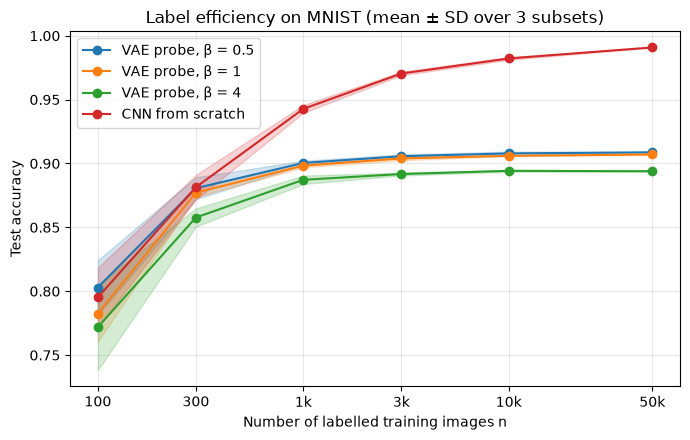

VAE probe, β = 0.5 {100: '0.803 ± 0.021', 300: '0.881 ± 0.009', 1000: '0.900 ± 0.002', 3000: '0.906 ± 0.001', 10000: '0.908 ± 0.001', 50000: '0.909 ± 0.000'}
VAE probe, β = 1 {100: '0.783 ± 0.022', 300: '0.877 ± 0.003', 1000: '0.898 ± 0.001', 3000: '0.904 ± 0.001', 10000: '0.906 ± 0.000', 50000: '0.907 ± 0.000'}
VAE probe, β = 4 {100: '0.772 ± 0.034', 300: '0.858 ± 0.007', 1000: '0.887 ± 0.003', 3000: '0.892 ± 0.001', 10000: '0.894 ± 0.001', 50000: '0.894 ± 0.000'}
CNN from scratch {100: '0.795 ± 0.023', 300: '0.881 ± 0.010', 1000: '0.943 ± 0.003', 3000: '0.970 ± 0.001', 10000: '0.982 ± 0.001', 50000: '0.991 ± 0.000'}


In [2]:
ns = [100, 300, 1000, 3000, 10000, 50000]
probe_results = json.load(open(ROOT / "outputs" / "probes" / "results.json"))

curves = {
    "VAE probe, β = 0.5": probe_curve(probe_results, "beta0.5"),
    "VAE probe, β = 1": probe_curve(probe_results, "beta1"),
    "VAE probe, β = 4": probe_curve(probe_results, "beta4"),
    "CNN from scratch": cnn_curve(ROOT / "outputs", ns, [0, 1, 2]),
}

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_label_efficiency(ax, curves, title="Label efficiency on MNIST (mean ± SD over 3 subsets)")
plt.tight_layout()
pdf.savefig(fig, bbox_inches="tight")
pdf.close()
plt.show()
for label, curve in curves.items():
    print(label, {n: f"{np.mean(a):.3f} ± {np.std(a, ddof=1):.3f}" for n, a in sorted(curve.items())})